In [30]:

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
import numpy as np
import random
import time

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch sürümü:", torch.__version__)
print("Kullanılan cihaz:", device)
print("Kütüphaneler başarıyla yüklendi.")


PyTorch sürümü: 2.11.0+cpu
Kullanılan cihaz: cpu
Kütüphaneler başarıyla yüklendi.


In [31]:

transform = transforms.ToTensor()

full_train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_size = 50000
val_size = 10000

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

batch_size = 128

train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=batch_size, shuffle=False
)

test_loader = DataLoader(
    test_dataset, batch_size=batch_size, shuffle=False
)

print("Train görüntü sayısı:", len(train_dataset))
print("Validation görüntü sayısı:", len(val_dataset))
print("Test görüntü sayısı:", len(test_dataset))
print("Görüntü boyutu:", full_train_dataset[0][0].shape)
print("Sınıf sayısı:", len(full_train_dataset.classes))


Train görüntü sayısı: 50000
Validation görüntü sayısı: 10000
Test görüntü sayısı: 10000
Görüntü boyutu: torch.Size([1, 28, 28])
Sınıf sayısı: 10


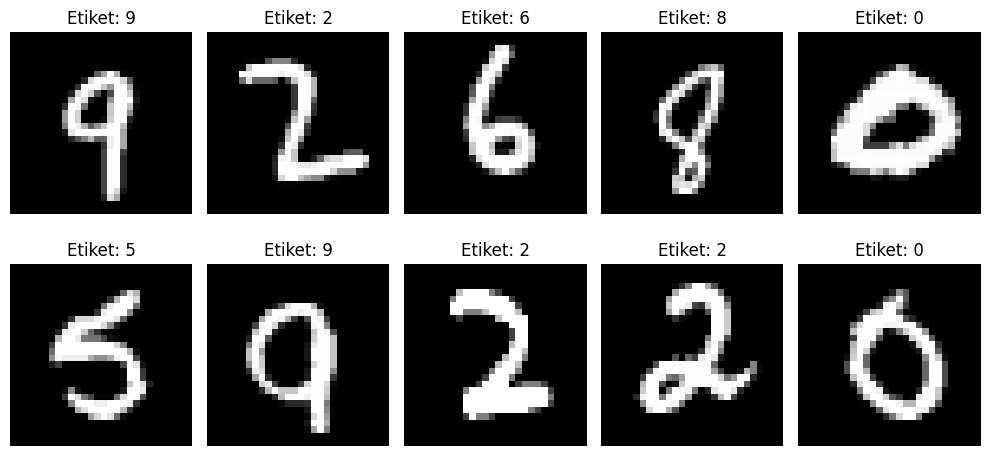

In [32]:

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Etiket: {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [33]:

class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


model = MLP().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(model)
print("\nKayıp fonksiyonu:", criterion)
print("Optimizer: Adam")
print("Öğrenme oranı: 0.001")
print("Model başarıyla oluşturuldu.")


MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)

Kayıp fonksiyonu: CrossEntropyLoss()
Optimizer: Adam
Öğrenme oranı: 0.001
Model başarıyla oluşturuldu.


In [34]:

num_epochs = 5

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

start_time = time.time()

for epoch in range(num_epochs):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_train_loss = running_loss / total
    epoch_train_acc = 100 * correct / total

    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    epoch_val_loss = val_running_loss / val_total
    epoch_val_acc = 100 * val_correct / val_total

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    train_accuracies.append(epoch_train_acc)
    val_accuracies.append(epoch_val_acc)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Train Accuracy: {epoch_train_acc:.2f}% | "
        f"Val Accuracy: {epoch_val_acc:.2f}%"
    )

training_time = time.time() - start_time

print(f"\nToplam eğitim süresi: {training_time:.2f} saniye")


Epoch [1/5] Train Loss: 0.3835 | Val Loss: 0.2043 | Train Accuracy: 89.28% | Val Accuracy: 93.77%
Epoch [2/5] Train Loss: 0.1481 | Val Loss: 0.1471 | Train Accuracy: 95.64% | Val Accuracy: 95.64%
Epoch [3/5] Train Loss: 0.1001 | Val Loss: 0.1223 | Train Accuracy: 97.01% | Val Accuracy: 96.28%
Epoch [4/5] Train Loss: 0.0742 | Val Loss: 0.1029 | Train Accuracy: 97.74% | Val Accuracy: 97.02%
Epoch [5/5] Train Loss: 0.0558 | Val Loss: 0.1089 | Train Accuracy: 98.27% | Val Accuracy: 96.75%

Toplam eğitim süresi: 47.86 saniye


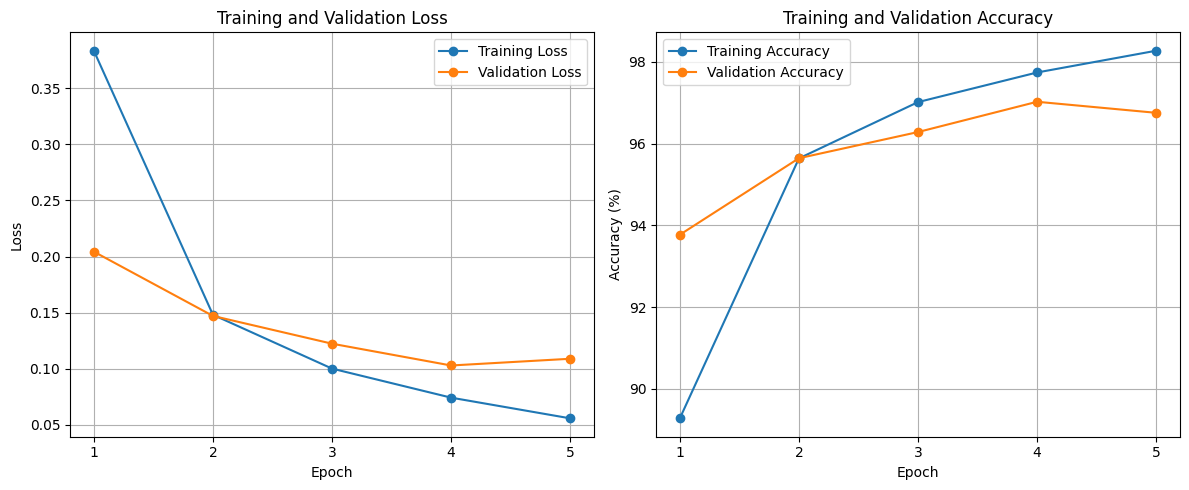

In [35]:

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, marker="o", label="Training Loss")
plt.plot(epochs, val_losses, marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, marker="o", label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("training_results.png", dpi=300, bbox_inches="tight")
plt.show()


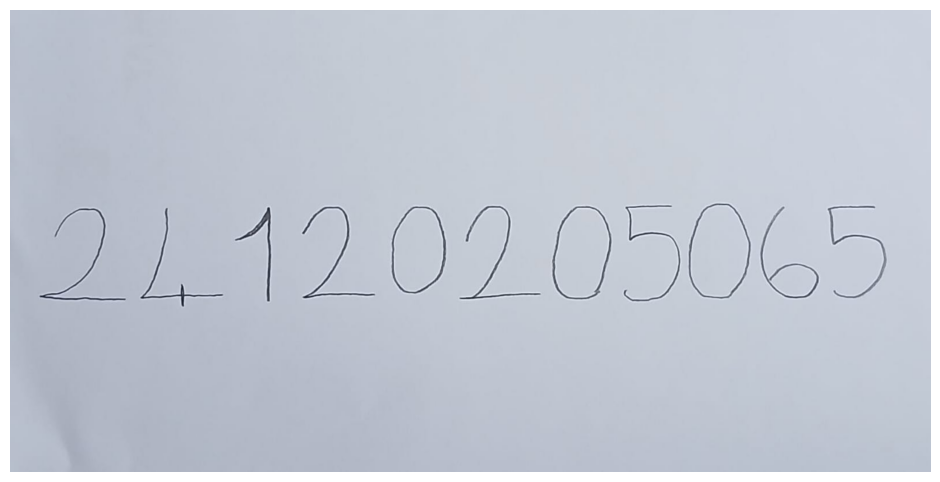

Fotoğraf boyutu: (1600, 803)


In [36]:
from PIL import Image
import matplotlib.pyplot as plt

image = Image.open(
    "/content/6770232b-304c-4534-acd1-9d90cddab5cc.jpg"
)

plt.figure(figsize=(12, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

print("Fotoğraf boyutu:", image.size)

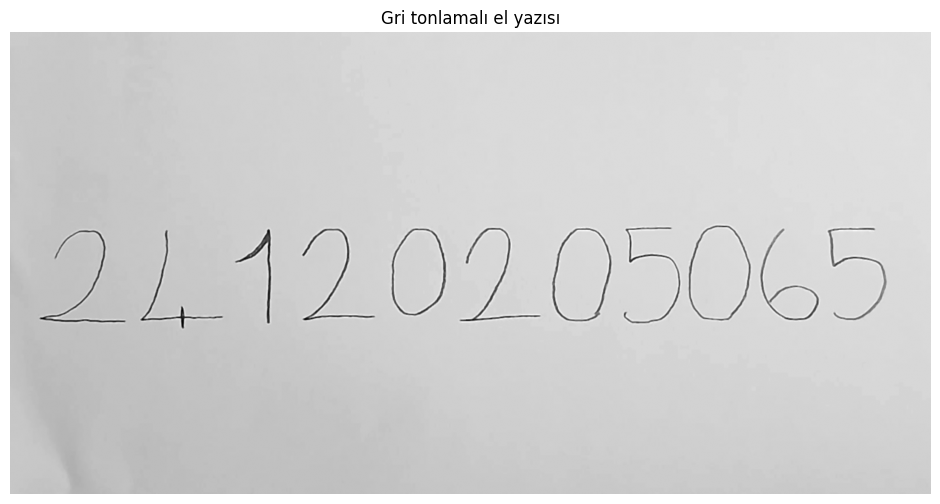

Piksel aralığı: 12 - 238


In [37]:
from PIL import ImageOps, ImageFilter
import numpy as np
import matplotlib.pyplot as plt

gray = image.convert("L")
gray = ImageOps.autocontrast(gray)
gray = gray.filter(ImageFilter.MedianFilter(size=3))

plt.figure(figsize=(14, 6))
plt.imshow(gray, cmap="gray")
plt.title("Gri tonlamalı el yazısı")
plt.axis("off")
plt.show()

print("Piksel aralığı:", np.array(gray).min(), "-", np.array(gray).max())

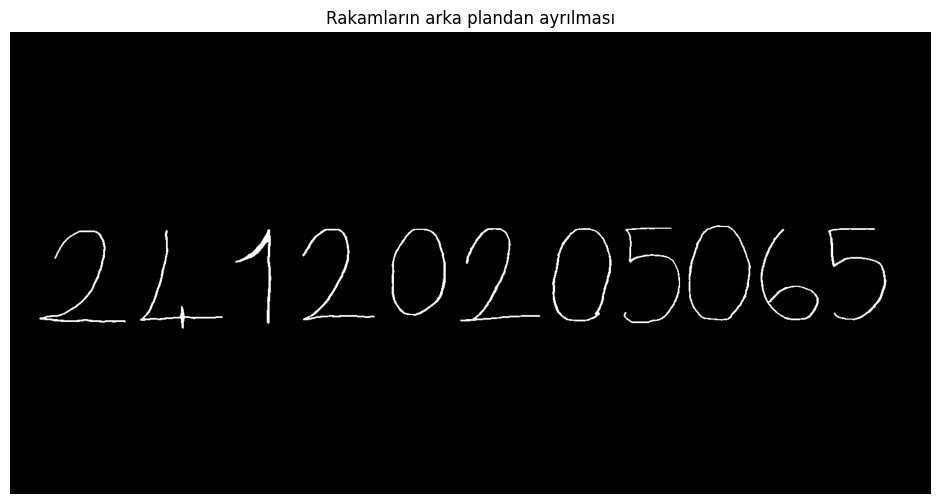

Görüntü boyutu: (803, 1600)
Rakam olarak algılanan piksel sayısı: 14407


In [38]:
threshold = 150
arr = np.array(gray)

binary = arr < threshold

plt.figure(figsize=(14, 6))
plt.imshow(binary, cmap="gray")
plt.title("Rakamların arka plandan ayrılması")
plt.axis("off")
plt.show()

print("Görüntü boyutu:", binary.shape)
print("Rakam olarak algılanan piksel sayısı:", np.sum(binary))

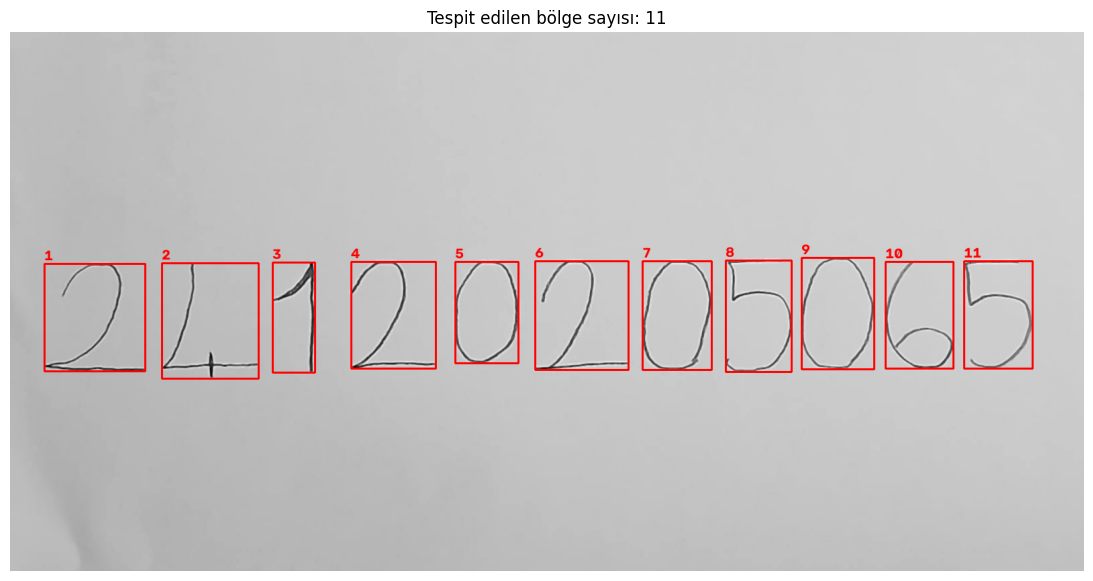

Tespit edilen bölge sayısı: 11
Kutu 1: x=51, y=345, genişlik=150, yükseklik=160
Kutu 2: x=226, y=344, genişlik=144, yükseklik=172
Kutu 3: x=391, y=343, genişlik=63, yükseklik=164
Kutu 4: x=508, y=342, genişlik=126, yükseklik=159
Kutu 5: x=663, y=342, genişlik=94, yükseklik=151
Kutu 6: x=782, y=341, genişlik=139, yükseklik=162
Kutu 7: x=942, y=341, genişlik=103, yükseklik=162
Kutu 8: x=1066, y=340, genişlik=98, yükseklik=166
Kutu 9: x=1179, y=336, genişlik=108, yükseklik=166
Kutu 10: x=1304, y=342, genişlik=101, yükseklik=159
Kutu 11: x=1421, y=341, genişlik=102, yükseklik=160


In [39]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

binary_uint8 = (binary.astype(np.uint8) * 255)

num_labels, labels_img, stats, centroids = cv2.connectedComponentsWithStats(
    binary_uint8, connectivity=8
)

boxes = []

for i in range(1, num_labels):
    x, y, w, h, area = stats[i]

    if area > 20 and h > 10 and w > 2:
        boxes.append((x, y, w, h, area))

boxes.sort(key=lambda box: box[0])

preview = cv2.cvtColor(np.array(gray), cv2.COLOR_GRAY2RGB)

for i, (x, y, w, h, area) in enumerate(boxes):
    cv2.rectangle(preview, (x, y), (x + w, y + h), (255, 0, 0), 2)
    cv2.putText(
        preview, str(i + 1), (x, max(20, y - 5)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2
    )

plt.figure(figsize=(16, 7))
plt.imshow(preview)
plt.title(f"Tespit edilen bölge sayısı: {len(boxes)}")
plt.axis("off")
plt.show()

print("Tespit edilen bölge sayısı:", len(boxes))
for i, box in enumerate(boxes):
    print(f"Kutu {i+1}: x={box[0]}, y={box[1]}, genişlik={box[2]}, yükseklik={box[3]}")

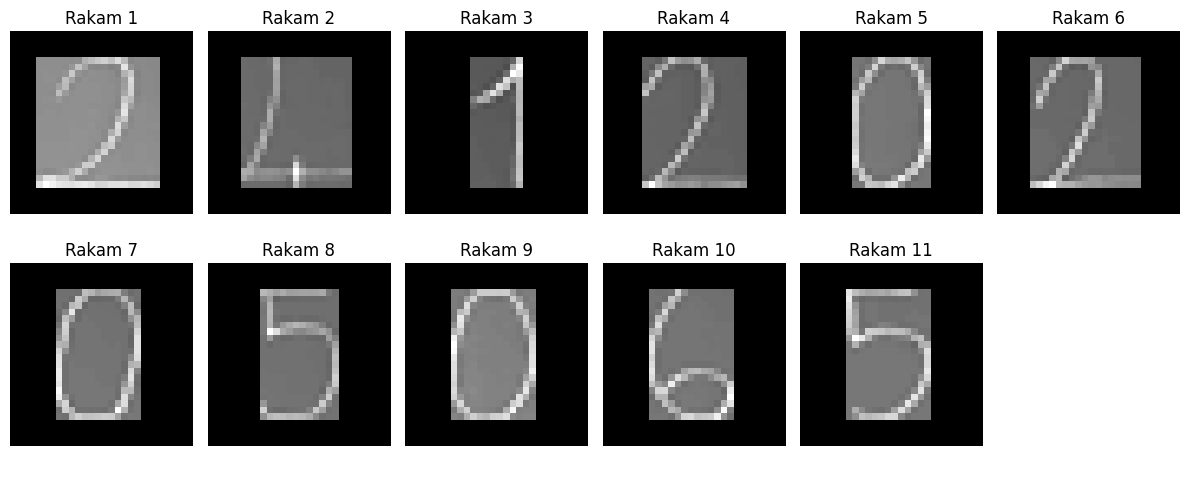

Hazırlanan rakam sayısı: 11
Her rakamın boyutu: (28, 28)


In [40]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import torch

digit_images = []

for x, y, w, h, area in boxes:
    digit = gray.crop((x, y, x + w, y + h))

    digit = ImageOps.invert(digit)
    digit.thumbnail((20, 20))

    canvas = Image.new("L", (28, 28), 0)

    paste_x = (28 - digit.width) // 2
    paste_y = (28 - digit.height) // 2

    canvas.paste(digit, (paste_x, paste_y))

    digit_array = np.array(canvas).astype(np.float32) / 255.0
    digit_images.append(digit_array)

fig, axes = plt.subplots(2, 6, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    if i < len(digit_images):
        ax.imshow(digit_images[i], cmap="gray")
        ax.set_title(f"Rakam {i+1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Hazırlanan rakam sayısı:", len(digit_images))
print("Her rakamın boyutu:", digit_images[0].shape)

In [41]:
model.eval()

digit_tensor = torch.tensor(
    np.array(digit_images),
    dtype=torch.float32
).unsqueeze(1).to(device)

with torch.no_grad():
    outputs = model(digit_tensor)
    probabilities = torch.softmax(outputs, dim=1)
    predictions = outputs.argmax(dim=1)

print("Gerçek okul numarası: 24120205065")
print("Modelin tahmini: ", end="")

for prediction in predictions.cpu().numpy():
    print(prediction, end="")

print("\n\nRakam bazında tahminler:")

for i, prediction in enumerate(predictions.cpu().numpy()):
    confidence = probabilities[i, prediction].item() * 100
    print(
        f"{i+1}. rakam: Tahmin={prediction}, "
        f"Güven={confidence:.2f}%"
    )

Gerçek okul numarası: 24120205065
Modelin tahmini: 88888888888

Rakam bazında tahminler:
1. rakam: Tahmin=8, Güven=42.47%
2. rakam: Tahmin=8, Güven=36.10%
3. rakam: Tahmin=8, Güven=53.59%
4. rakam: Tahmin=8, Güven=67.30%
5. rakam: Tahmin=8, Güven=51.94%
6. rakam: Tahmin=8, Güven=54.08%
7. rakam: Tahmin=8, Güven=42.50%
8. rakam: Tahmin=8, Güven=54.14%
9. rakam: Tahmin=8, Güven=42.40%
10. rakam: Tahmin=8, Güven=49.87%
11. rakam: Tahmin=8, Güven=46.56%


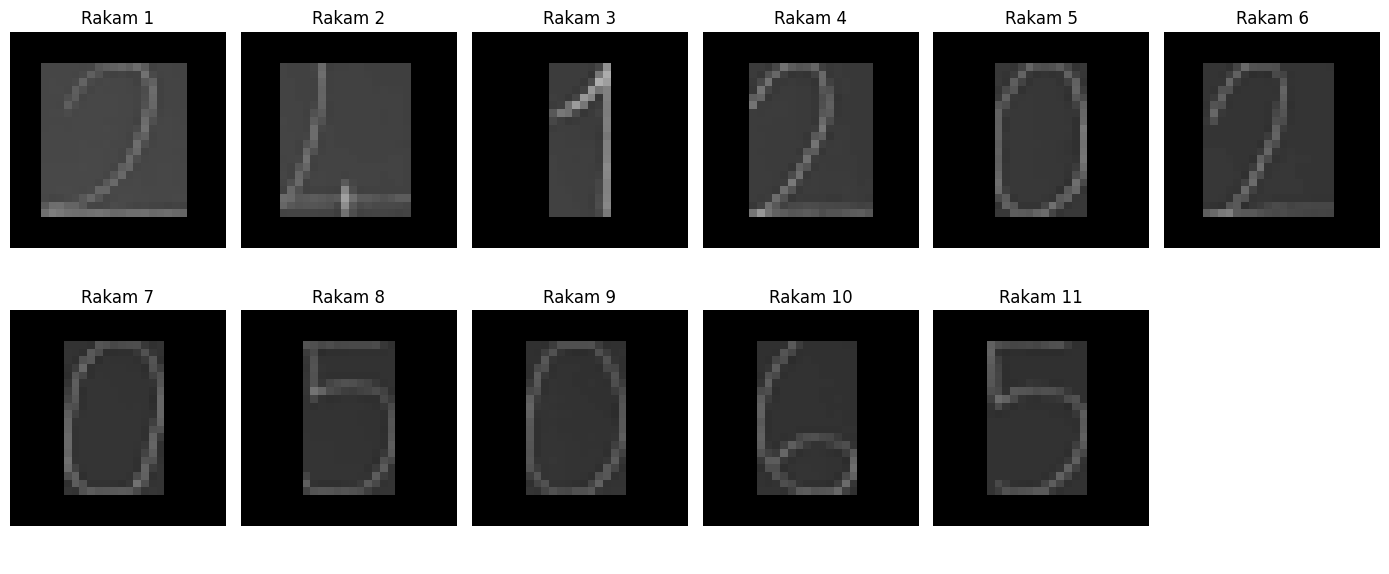

In [42]:
fig, axes = plt.subplots(2, 6, figsize=(14, 6))

for i, ax in enumerate(axes.flat):
    if i < len(digit_images):
        ax.imshow(digit_images[i], cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"Rakam {i+1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

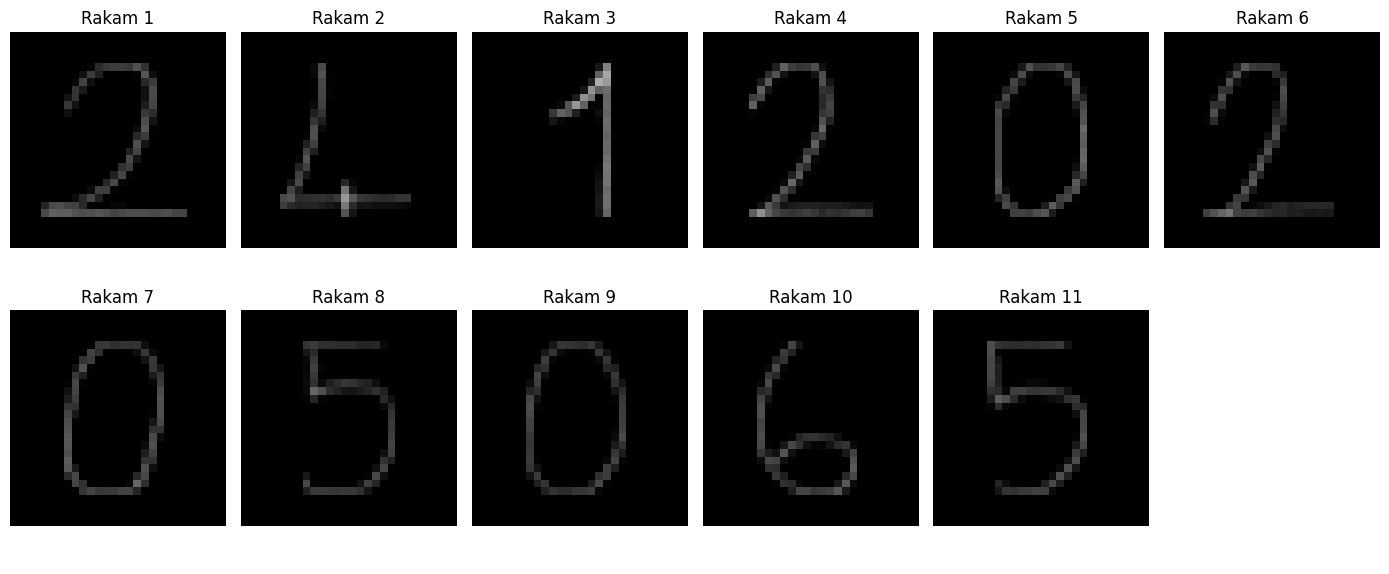

In [43]:
digit_images = []

for x, y, w, h, area in boxes:
    digit = gray.crop((x, y, x + w, y + h))
    digit_array = np.array(digit)

    # Rakamı beyaz, arka planı siyah yap
    digit_array = 255 - digit_array

    # Rakamın etrafındaki boşluğu kaldır
    digit_array = np.where(digit_array > 80, digit_array, 0).astype(np.uint8)

    digit = Image.fromarray(digit_array)
    digit.thumbnail((20, 20))

    canvas = Image.new("L", (28, 28), 0)
    paste_x = (28 - digit.width) // 2
    paste_y = (28 - digit.height) // 2
    canvas.paste(digit, (paste_x, paste_y))

    digit_images.append(np.array(canvas, dtype=np.float32) / 255.0)

fig, axes = plt.subplots(2, 6, figsize=(14, 6))

for i, ax in enumerate(axes.flat):
    if i < len(digit_images):
        ax.imshow(digit_images[i], cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"Rakam {i+1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [44]:
model.eval()

digit_tensor = torch.tensor(
    np.array(digit_images),
    dtype=torch.float32
).unsqueeze(1).to(device)

with torch.no_grad():
    outputs = model(digit_tensor)
    probabilities = torch.softmax(outputs, dim=1)
    predictions = outputs.argmax(dim=1)

print("Gerçek okul numarası: 24120205065")
print("Modelin tahmini: ", "".join(map(str, predictions.cpu().numpy())))

for i, prediction in enumerate(predictions.cpu().numpy()):
    confidence = probabilities[i, prediction].item() * 100
    print(f"{i+1}. rakam: {prediction} (Güven: {confidence:.2f}%)")

Gerçek okul numarası: 24120205065
Modelin tahmini:  25920205055
1. rakam: 2 (Güven: 56.49%)
2. rakam: 5 (Güven: 32.15%)
3. rakam: 9 (Güven: 21.50%)
4. rakam: 2 (Güven: 55.91%)
5. rakam: 0 (Güven: 37.51%)
6. rakam: 2 (Güven: 50.91%)
7. rakam: 0 (Güven: 25.84%)
8. rakam: 5 (Güven: 33.41%)
9. rakam: 0 (Güven: 23.07%)
10. rakam: 5 (Güven: 26.32%)
11. rakam: 5 (Güven: 27.81%)


In [45]:
real_digits = [int(d) for d in "24120205065"]
predicted_digits = predictions.cpu().numpy().tolist()

print("Rakam | Gerçek | Tahmin | Sonuç")
print("-" * 35)

correct_count = 0

for i, (real, predicted) in enumerate(
    zip(real_digits, predicted_digits), start=1
):
    result = "Doğru" if real == predicted else "Yanlış"

    if real == predicted:
        correct_count += 1

    print(f"{i:5} | {real:6} | {predicted:6} | {result}")

print("-" * 35)
print(f"Doğru rakam sayısı: {correct_count}/11")
print(f"El yazısı doğruluğu: {correct_count / 11 * 100:.2f}%")

Rakam | Gerçek | Tahmin | Sonuç
-----------------------------------
    1 |      2 |      2 | Doğru
    2 |      4 |      5 | Yanlış
    3 |      1 |      9 | Yanlış
    4 |      2 |      2 | Doğru
    5 |      0 |      0 | Doğru
    6 |      2 |      2 | Doğru
    7 |      0 |      0 | Doğru
    8 |      5 |      5 | Doğru
    9 |      0 |      0 | Doğru
   10 |      6 |      5 | Yanlış
   11 |      5 |      5 | Doğru
-----------------------------------
Doğru rakam sayısı: 8/11
El yazısı doğruluğu: 72.73%


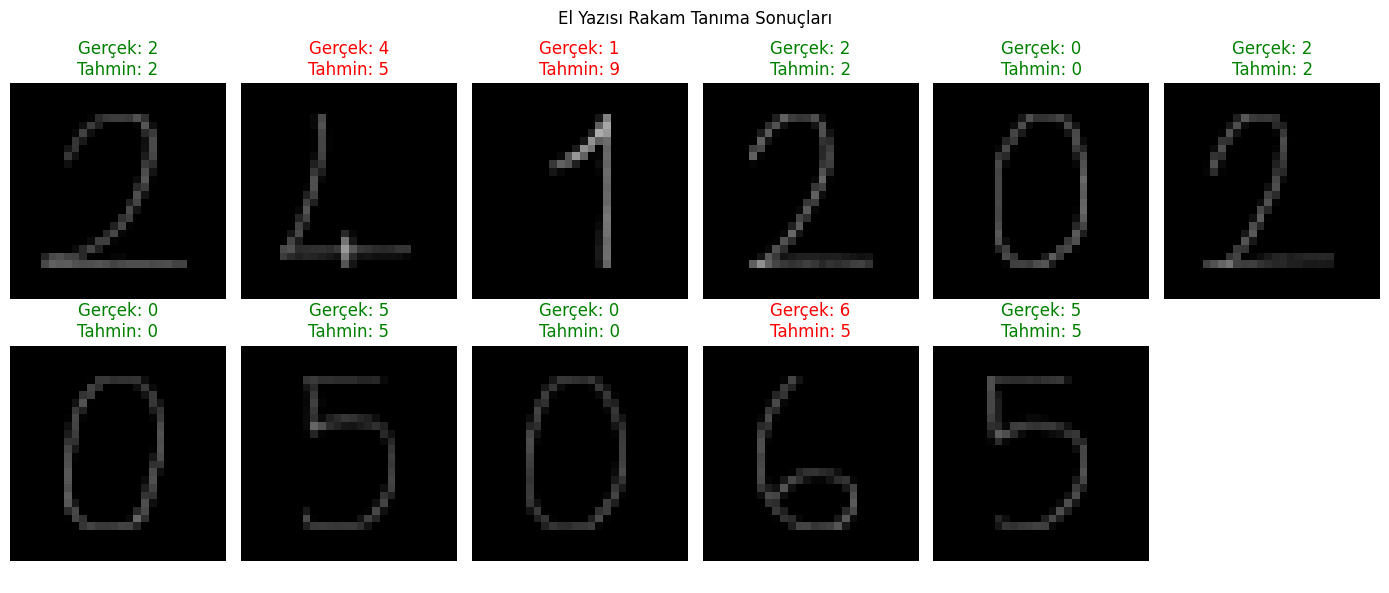

In [46]:
real_digits = [int(d) for d in "24120205065"]
predicted_digits = predictions.cpu().numpy().tolist()

fig, axes = plt.subplots(2, 6, figsize=(14, 6))

for i, ax in enumerate(axes.flat):
    if i < len(digit_images):
        ax.imshow(digit_images[i], cmap="gray", vmin=0, vmax=1)

        if real_digits[i] == predicted_digits[i]:
            color = "green"
        else:
            color = "red"

        ax.set_title(
            f"Gerçek: {real_digits[i]}\nTahmin: {predicted_digits[i]}",
            color=color
        )

    ax.axis("off")

plt.suptitle("El Yazısı Rakam Tanıma Sonuçları")
plt.tight_layout()
plt.savefig("handwriting_results.png", dpi=300, bbox_inches="tight")
plt.show()

In [47]:

class MLP2(nn.Module):
    def __init__(self):
        super(MLP2, self).__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)


model2 = MLP2().to(device)
criterion2 = nn.CrossEntropyLoss()
optimizer2 = optim.Adam(model2.parameters(), lr=0.001)

epochs2 = 5
train_losses2 = []
val_losses2 = []
train_accs2 = []
val_accs2 = []

start2 = time.time()

for epoch in range(epochs2):
    model2.train()
    total_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer2.zero_grad()
        outputs = model2(images)
        loss = criterion2(outputs, labels)
        loss.backward()
        optimizer2.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_losses2.append(total_loss / total)
    train_accs2.append(100 * correct / total)

    model2.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model2(images)
            loss = criterion2(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_losses2.append(val_loss / val_total)
    val_accs2.append(100 * val_correct / val_total)

    print(
        f"Epoch {epoch+1}/{epochs2} | "
        f"Train Loss: {train_losses2[-1]:.4f} | "
        f"Val Loss: {val_losses2[-1]:.4f} | "
        f"Train Acc: {train_accs2[-1]:.2f}% | "
        f"Val Acc: {val_accs2[-1]:.2f}%"
    )

time2 = time.time() - start2

print(f"\nİkinci model eğitim süresi: {time2:.2f} saniye")
print(f"En yüksek doğrulama doğruluğu: {max(val_accs2):.2f}%")


Epoch 1/5 | Train Loss: 0.4721 | Val Loss: 0.2478 | Train Acc: 86.75% | Val Acc: 92.82%
Epoch 2/5 | Train Loss: 0.1931 | Val Loss: 0.1763 | Train Acc: 94.46% | Val Acc: 94.73%
Epoch 3/5 | Train Loss: 0.1378 | Val Loss: 0.1565 | Train Acc: 95.96% | Val Acc: 95.33%
Epoch 4/5 | Train Loss: 0.1073 | Val Loss: 0.1276 | Train Acc: 96.79% | Val Acc: 96.14%
Epoch 5/5 | Train Loss: 0.0839 | Val Loss: 0.1206 | Train Acc: 97.49% | Val Acc: 96.37%

İkinci model eğitim süresi: 43.31 saniye
En yüksek doğrulama doğruluğu: 96.37%


In [48]:


print("\nMODEL KARŞILAŞTIRMASI")
print("-" * 55)
print(f"{'Ölçüm':<28}{'Model 1':>12}{'Model 2':>12}")
print("-" * 55)
print(f"{'Gizli katmanlar':<28}{'256, 128':>12}{'128, 64':>12}")
print(f"{'En iyi validation accuracy':<28}{max(val_accuracies):>11.2f}%{max(val_accs2):>11.2f}%")
print(f"{'Eğitim süresi (sn)':<28}{training_time:>12.2f}{time2:>12.2f}")

print("\nModel seçimi: Validation doğruluğu daha yüksek olan Model 1.")
print(f"Model 1 en yüksek validation accuracy: {max(val_accuracies):.2f}%")



MODEL KARŞILAŞTIRMASI
-------------------------------------------------------
Ölçüm                            Model 1     Model 2
-------------------------------------------------------
Gizli katmanlar                 256, 128     128, 64
En iyi validation accuracy        97.02%      96.37%
Eğitim süresi (sn)                 47.86       43.31

Model seçimi: Validation doğruluğu daha yüksek olan Model 1.
Model 1 en yüksek validation accuracy: 97.02%


In [49]:

model.eval()

test_correct = 0
test_total = 0
test_running_loss = 0.0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        test_correct += (predictions == labels).sum().item()
        test_total += labels.size(0)

test_loss = test_running_loss / test_total
test_accuracy = 100 * test_correct / test_total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Test edilen görüntü sayısı: {test_total}")
print(f"Eğitim süresi: {training_time:.2f} saniye")


Test Loss: 0.0911
Test Accuracy: 97.29%
Test edilen görüntü sayısı: 10000
Eğitim süresi: 47.86 saniye


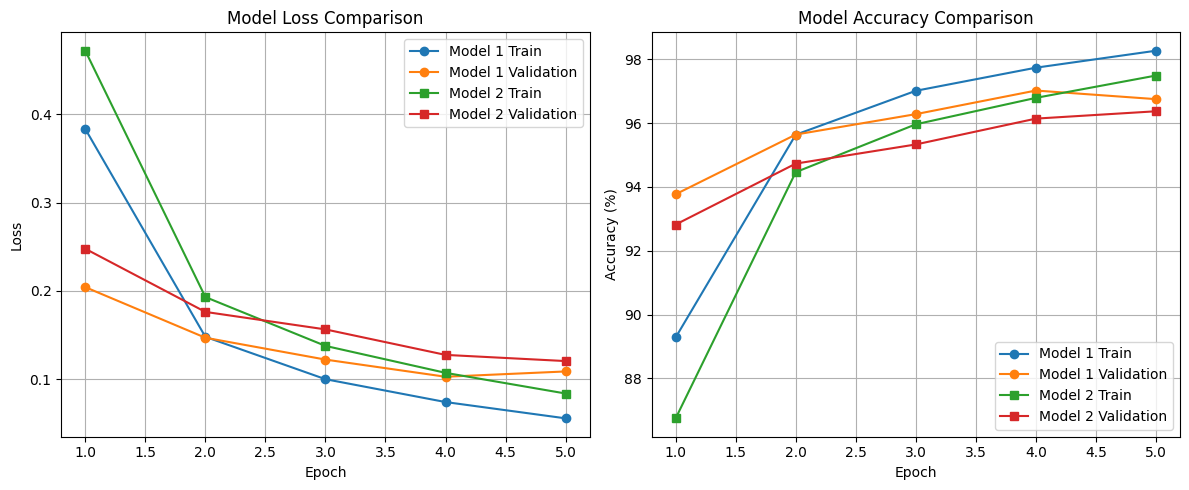

In [50]:

epochs1 = range(1, len(train_losses) + 1)
epochs2_range = range(1, len(train_losses2) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs1, train_losses, marker="o", label="Model 1 Train")
plt.plot(epochs1, val_losses, marker="o", label="Model 1 Validation")
plt.plot(epochs2_range, train_losses2, marker="s", label="Model 2 Train")
plt.plot(epochs2_range, val_losses2, marker="s", label="Model 2 Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model Loss Comparison")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs1, train_accuracies, marker="o", label="Model 1 Train")
plt.plot(epochs1, val_accuracies, marker="o", label="Model 1 Validation")
plt.plot(epochs2_range, train_accs2, marker="s", label="Model 2 Train")
plt.plot(epochs2_range, val_accs2, marker="s", label="Model 2 Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Comparison")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
